# 00 · Exploración inicial (Hito 1) · Sala de Crisis COVID-19

**Equipo GD 2026-2 · IN1232C**

Este notebook resuelve el **punto de partida** del proyecto sobre los reportes diarios de
Johns Hopkins de **enero a junio de 2020**:

1. Cargar `01-22-2020.csv` y describir sus filas, columnas y tipos.
2. Contar nulos por columna e interpretar qué significan en este conjunto.
3. Estandarizar nombres a `snake_case` y fechas a `AAAA-MM-DD`.
4. Unir enero–junio 2020 en un solo DataFrame (aparecen los 2 primeros cambios de esquema).
5. Top 10 países con más casos acumulados al 30-jun-2020 y evolución de Chile (gráficos).
6. Perfilado automático y **3 observaciones**.

> Ejecutar con el kernel del proyecto. Los datos crudos se descargan a `data/raw/` y
> **no se suben al repositorio**.


In [1]:
import os, sys, time, zipfile, io, json
import datetime as dt
from pathlib import Path
from urllib.request import urlopen, Request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 40)
plt.rcParams['figure.figsize'] = (11, 4)

# Rutas: funciona en el repo (notebooks/) y en Colab
PROJECT = Path.cwd()
if not (PROJECT / 'data').exists():
    PROJECT = PROJECT.parent
RAW = PROJECT / 'data' / 'raw' / 'daily_reports'
print('Proyecto:', PROJECT)

Proyecto: C:\Users\hecto\Desktop\Nueva carpeta (2)


## 1 · Cargar el primer reporte: `01-22-2020.csv`

Descargamos (una sola vez, con caché local) el primer reporte diario de JHU.
La descarga usa las URLs «raw» de GitHub y **no clona el repositorio**: pesa mucho
por su historial git.

In [2]:
URL_BASE = (
    'https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/'
    'csse_covid_19_data/csse_covid_19_daily_reports/{nombre}'
)

def descargar(nombre: str) -> bytes:
    '''Descarga un CSV de JHU con caché local en data/raw (idempotente).'''
    destino = RAW / nombre
    if destino.exists() and destino.stat().st_size > 0:
        return destino.read_bytes()
    RAW.mkdir(parents=True, exist_ok=True)
    for intento in range(3):
        try:
            with urlopen(URL_BASE.format(nombre=nombre), timeout=30) as r:
                datos = r.read()
            if len(datos) < 50:
                raise IOError('respuesta demasiado corta')
            destino.write_bytes(datos)
            return datos
        except Exception as e:
            if intento == 2:
                raise
            time.sleep(2)

pr1 = pd.read_csv(io.BytesIO(descargar('01-22-2020.csv')))
print('filas:', len(pr1), '| columnas:', len(pr1.columns))

filas: 76 | columnas: 6


In [3]:
pr1.head()

,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered
0,Anhui,Mainland China,1/22/2020 17:00,1.0,NaN,NaN
1,Beijing,Mainland China,1/22/2020 17:00,14.0,NaN,NaN
2,Chongqing,Mainland China,1/22/2020 17:00,6.0,NaN,NaN
3,Fujian,Mainland China,1/22/2020 17:00,1.0,NaN,NaN
4,Gansu,Mainland China,1/22/2020 17:00,NaN,NaN,NaN


In [4]:
pr1.shape

(76, 6)

In [5]:
pr1.dtypes

Province/State     object
Country/Region     object
Last Update        object
Confirmed         float64
Deaths            float64
Recovered         float64
dtype: object

## 2 · Nulos por columna y qué significan

En este conjunto los nulos **no son errores de lectura**: significados reales del mundo:

- `Province/State` nulo → el reporte es a **nivel país** (no hay subterritorio).
- `Deaths` / `Recovered` nulos en enero → la información **aún no se reportaba**
  para ese territorio, no es que nadie se haya recuperado ni fallecido.
- Más adelante (esquema 3, desde 22-mar), `FIPS` / `Admin2` nulos → la fila no es de
  EE.UU. (esos campos son del condado estadounidense).

In [6]:
nulos = pr1.isna().sum().to_frame('nulos')
nulos['% del total'] = (100 * nulos['nulos'] / len(pr1)).round(1)
interpretacion = {
    'Province/State': 'Fila a nivel país (sin provincia/estado)',
    'Confirmed': 'No informado para ese territorio en la fecha (≠ 0 casos)',
    'Deaths': 'No informado / aún sin reporte de fallecidos (≠ 0)',
    'Recovered': 'No informado / aún sin reporte de recuperados (≠ 0)',
}
nulos['interpretación'] = [interpretacion.get(c, '—') for c in nulos.index]
nulos

,nulos,% del total,interpretación
Province/State,12,15.8,Fila a nivel país (sin provincia/estado)
Country/Region,0,0.0,—
Last Update,0,0.0,—
Confirmed,10,13.2,No informado para ese territorio en la fecha (...
Deaths,37,48.7,No informado / aún sin reporte de fallecidos (...
Recovered,37,48.7,No informado / aún sin reporte de recuperados ...


## 3 · Estandarización: `snake_case` y fechas ISO

Los cinco esquemas de JHU nombran lo mismo de formas distintas
(`Province/State` ≠ `Province_State`, `Lat` ≠ `Latitude`…). Definimos el
mapa único bajo el que vivirán **todas** las capas del proyecto. Las fechas llegan en
al menos siete formatos (`1/23/20 17:00`, `1/22/2020 17:00`, ISO…): las normalizamos a
`AAAA-MM-DD` con una lista explícita de formatos, para no depender de la inferencia
automática.

In [7]:
MAPA_COLUMNAS = {
    # esquema 1
    'Province/State': 'province_state', 'Country/Region': 'country_region',
    'Last Update': 'last_update',
    # esquema 3 en adelante
    'FIPS': 'fips', 'Admin2': 'admin2', 'Province_State': 'province_state',
    'Country_Region': 'country_region', 'Last_Update': 'last_update',
    # coordenadas (3 nombre distintos, 1 estándar)
    'Latitude': 'lat', 'Longitude': 'lon', 'Lat': 'lat', 'Long_': 'lon',
    # métricas
    'Confirmed': 'confirmed', 'Deaths': 'deaths', 'Recovered': 'recovered',
    'Active': 'active', 'Combined_Key': 'combined_key',
    # renombrados del esquema 5
    'Incidence_Rate': 'incident_rate', 'Incident_Rate': 'incident_rate',
    'Case-Fatality_Ratio': 'case_fatality_ratio', 'Case_Fatality_Ratio': 'case_fatality_ratio',
}

def estandarizar(df: pd.DataFrame) -> pd.DataFrame:
    df = df.rename(columns=MAPA_COLUMNAS)
    # última actualización → fecha AAAA-MM-DD (los formatos cambiaron en el tiempo)
    s = df['last_update'].astype('string').str.strip()
    fecha = pd.Series(pd.NaT, index=s.index)
    for fmt in ('%m/%d/%y %H:%M', '%m/%d/%Y %H:%M',
                '%m/%d/%y %H:%M:%S', '%m/%d/%Y %H:%M:%S',
                '%Y-%m-%d %H:%M:%S', '%Y-%m-%dT%H:%M:%S', '%Y-%m-%d %H:%M'):
        pend = fecha.isna() & s.notna()
        if pend.any():
            fecha[pend] = pd.to_datetime(s[pend], format=fmt, errors='coerce')
    df['last_update'] = fecha.dt.strftime('%Y-%m-%d')
    return df

pr1_std = estandarizar(pr1)
pr1_std[['province_state', 'country_region', 'last_update',
         'confirmed', 'deaths', 'recovered']].head()

,province_state,country_region,last_update,confirmed,deaths,recovered
0,Anhui,Mainland China,2020-01-22,1.0,NaN,NaN
1,Beijing,Mainland China,2020-01-22,14.0,NaN,NaN
2,Chongqing,Mainland China,2020-01-22,6.0,NaN,NaN
3,Fujian,Mainland China,2020-01-22,1.0,NaN,NaN
4,Gansu,Mainland China,2020-01-22,NaN,NaN,NaN


## 4 · Unir enero–junio 2020 en un solo DataFrame

Dentro de la ventana hay **tres cambios de esquema** (más de los dos que menciona el
enunciado): el **1-mar** se agregan `Latitude/Longitude` (etapa 2), el **22-mar** pasa a
`FIPS, Admin2, Province_State…` (etapa 3) y el **29-may** se agregan `Incidence_Rate` y
`Case-Fatality_Ratio` (etapa 4). Detectamos la etapa por las columnas presentes y
alineamos todo al mapa estándar. Además:
- guardamos la **fecha del reporte** desde el nombre del archivo (`MM-DD-YYYY.csv`),
  que es la fuente de verdad temporal, y marcamos la **etapa** de cada fila
  (insumo del diccionario de datos del Hito 2).

In [8]:
def rango_fechas(d1: dt.date, d2: dt.date):
    d = d1
    while d <= d2:
        yield d
        d += dt.timedelta(days=1)

def etapa_parcial(cols: set[str]) -> int:
    if {'Incidence_Rate', 'Incident_Rate', 'Case_Fatality_Ratio'} & cols:
        return 4
    if 'FIPS' in cols:
        return 3
    if 'Latitude' in cols:
        return 2
    return 1

fils = []
for d in rango_fechas(dt.date(2020, 1, 22), dt.date(2020, 6, 30)):
    nombre = f"{d:%m-%d-%Y}.csv"
    try:
        crudo = pd.read_csv(io.BytesIO(descargar(nombre)), low_memory=False)
    except FileNotFoundError:
        print('sin archivo (JHU lo omitió):', nombre)
        continue
    etapa = etapa_parcial(set(crudo.columns))
    df = estandarizar(crudo)
    df['fecha_reporte'] = f"{d:%Y-%m-%d}"
    df['etapa'] = etapa
    fils.append(df)

df = pd.concat(fils, ignore_index=True)
# numéricos de forma consistente (algunos CSV traen separadores raros)
for c in ['confirmed', 'deaths', 'recovered', 'active', 'lat', 'lon']:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')

print('DataFrame unificado:', df.shape)
print('por etapa →', df['etapa'].value_counts().sort_index().to_dict())

DataFrame unificado: (350945, 16)
por etapa → {1: 4242, 2: 5555, 3: 217486, 4: 123662}


In [9]:
# ¿qué columna existe desde qué fecha? (insumo del diccionario R2)
extens = {}
for c in ['lat', 'lon', 'fips', 'admin2', 'active', 'combined_key',
          'incident_rate', 'case_fatality_ratio']:
    v = df.loc[df[c].notna(), 'fecha_reporte'].min()
    extens[c] = f"desde {v}" if pd.notna(v) else 'no aparece en la ventana'
pd.Series(extens).to_frame('primera aparición')

,primera aparición
lat,desde 2020-03-01
lon,desde 2020-03-01
fips,desde 2020-03-22
admin2,desde 2020-03-22
active,desde 2020-03-22
combined_key,desde 2020-03-22
incident_rate,desde 2020-05-29
case_fatality_ratio,desde 2020-05-29


## 5 · Top 10 países al 30-jun-2020 y evolución de Chile

Cuidado con el doble conteo: hacia el 30-junio **Chile ya está por regiones** y muchos
países por provincias, así que sumamos por país en la fecha de corte.

In [10]:
top10 = (df.loc[df['fecha_reporte'] == '2020-06-30']
           .groupby('country_region', as_index=False)['confirmed'].sum()
           .sort_values('confirmed', ascending=False).head(10))
top10

,country_region,confirmed
183,US,2653658.0
24,Brazil,1412669.0
145,Russia,646929.0
80,India,585493.0
187,United Kingdom,314157.0
139,Peru,285213.0
36,Chile,279393.0
164,Spain,249271.0
86,Italy,240578.0
82,Iran,227662.0


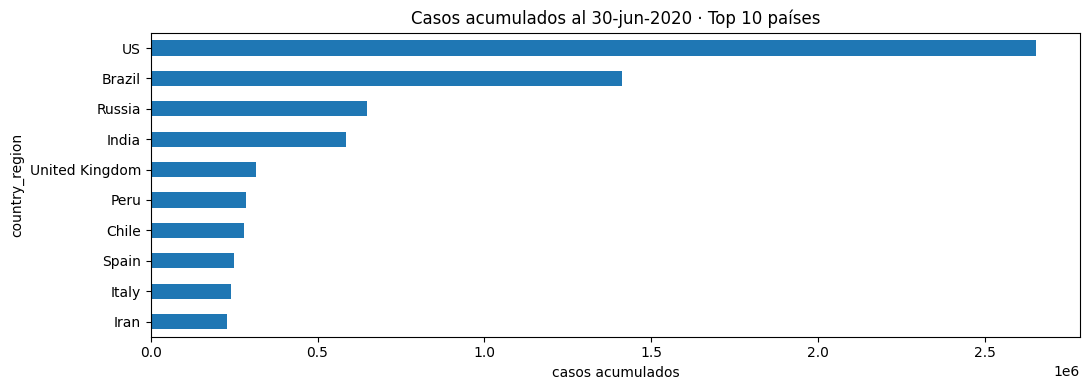

In [11]:
ax = top10.iloc[::-1].plot.barh(x='country_region', y='confirmed', legend=False,
                                title='Casos acumulados al 30-jun-2020 · Top 10 países')
ax.set_xlabel('casos acumulados')
plt.tight_layout()
plt.show()

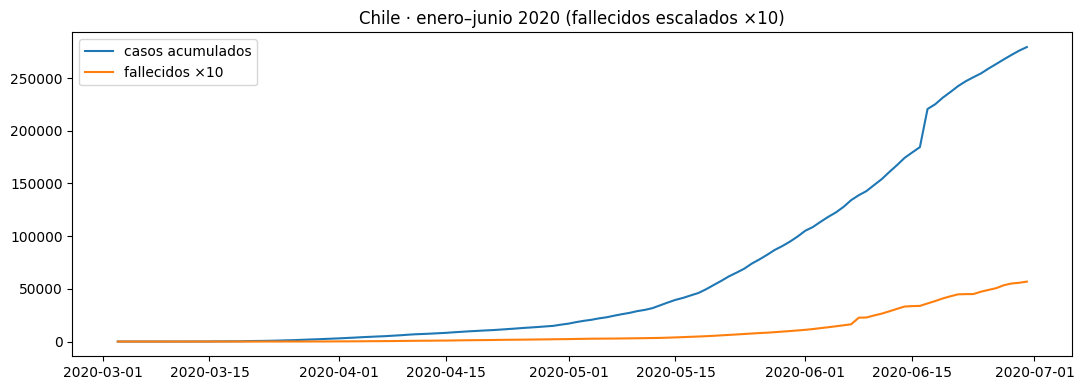

primera fecha con regiones: 2020-05-20 | días con filas regionales: 42 | territorios distintos: 17


,filas con provincia
fecha_reporte,
2020-06-23,17
2020-06-24,17
2020-06-25,17
2020-06-26,17
2020-06-27,17
2020-06-28,17
2020-06-29,17
2020-06-30,17


In [12]:
chile_linea = (df.loc[df['country_region'] == 'Chile']
                 .groupby('fecha_reporte', as_index=False)[['confirmed', 'deaths']].sum())
chile_linea['fecha_reporte'] = pd.to_datetime(chile_linea['fecha_reporte'])

fig, ax = plt.subplots()
ax.plot(chile_linea['fecha_reporte'], chile_linea['confirmed'], label='casos acumulados')
ax.plot(chile_linea['fecha_reporte'], chile_linea['deaths'] * 10, label='fallecidos ×10')
ax.set_title('Chile · enero–junio 2020 (fallecidos escalados ×10)')
ax.legend()
plt.tight_layout()
plt.show()

# el cambio de granularidad es visible: hasta el 19-may Chile es una fila país;
# desde el 20-may son 16 regiones + Unknown (la suma sigue siendo el total del país)
fila_chile = df.loc[df['country_region'] == 'Chile']
dias = (fila_chile.assign(con_region=fila_chile['province_state'].notna())
                  .groupby('fecha_reporte')['con_region'].sum())
print('primera fecha con regiones:', dias[dias > 0].index.min(),
      '| días con filas regionales:', int((dias > 0).sum()),
      '| territorios distintos:', fila_chile['province_state'].nunique())
dias.tail(8).rename('filas con provincia').to_frame()

## 6 · Perfilado automático y observaciones

Usamos `ydata-profiling` si está instalado (reporte HTML completo); si no, un perfil
mínimo con pandas. El reporte se guarda en `data/profile/` (gitignored).

In [13]:
salida = PROJECT / 'data' / 'profile'
salida.mkdir(parents=True, exist_ok=True)

# paquete vigente: fg-data-profiling; respaldo: ydata-profiling
ProfileReport = None
try:
    from data_profiling import ProfileReport
except ImportError:
    try:
        from ydata_profiling import ProfileReport
    except ImportError:
        pass

if ProfileReport is not None:
    perfil = ProfileReport(df, title='COVID-19 · enero-junio 2020',
                           minimal=True, progress_bar=False)
    perfil.to_file(salida / 'perfilado_exploracion.html')
    print('Reporte completo →', (salida / 'perfilado_exploracion.html').resolve())
else:
    print('Sin librería de perfilado instalada → resumen manual')

# el grano real es territorio × día: país + provincia + condado (admin2, EE.UU.)
llave = ['fecha_reporte', 'province_state', 'country_region', 'admin2']
resumen = pd.DataFrame({
    'valor': [
        f'{len(df):,}',
        str(df.shape[1]),
        f'{int(df.duplicated(subset=llave).sum()):,}',
        f'{df.isna().mean().mean() * 100:.2f}%',
        f'{int(df.duplicated().sum()):,}',
    ]}, index=['filas', 'columnas', 'duplicados (llave completa)', '% celdas nulas',
               'filas duplicadas exactas'])
resumen

  0%|          | 0/16 [00:00<?, ?it/s]

  6%|▋         | 1/16 [00:02<00:33,  2.20s/it]

 25%|██▌       | 4/16 [00:03<00:09,  1.23it/s]

 31%|███▏      | 5/16 [00:03<00:07,  1.48it/s]

 38%|███▊      | 6/16 [00:04<00:05,  1.92it/s]

 50%|█████     | 8/16 [00:04<00:03,  2.45it/s]

... (3 outputs left out)

 81%|████████▏ | 13/16 [00:08<00:01,  1.57it/s]

100%|██████████| 16/16 [00:08<00:00,  1.90it/s]

Reporte completo → C:\Users\hecto\Desktop\Nueva carpeta (2)\data\profile\perfilado_exploracion.html


,valor
filas,"350,945"
columnas,16
duplicados (llave completa),3
% celdas nulas,11.28%
filas duplicadas exactas,1


In [14]:
pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    '% nulos': (df.isna().mean() * 100).round(1),
    'únicos': df.nunique(dropna=True),
})

,tipo,nulos,% nulos,únicos
province_state,object,22249,6.3,730
country_region,object,0,0.0,246
last_update,object,0,0.0,163
confirmed,float64,28,0.0,15173
deaths,float64,432,0.1,3806
recovered,float64,385,0.1,7853
fecha_reporte,object,0,0.0,161
etapa,int64,0,0.0,4
lat,float64,10694,3.0,4276
lon,float64,10694,3.0,4306


### Tres observaciones del perfilado

1. **La cobertura de columnas crece con el tiempo y no es homogénea.** `lat`/`lon` no
   existen antes del 1-mar-2020; `fips`, `admin2`, `active` y `combined_key` aparecen el
   22-mar-2020; `incident_rate` y `case_fatality_ratio`, el 29-may-2020. Cualquier
   análisis que use esas columnas debe recortar su ventana: no son «nulos» aleatorios,
   son **columnas que aún no existían**.
2. **Gran parte de los nulos es informativa, no ruido.** En el primer reporte (22-ene),
   el 48,7% de `deaths` y `recovered` son nulos porque aún no se reportaban; en toda la
   ventana el 11,28% de las celdas está nulo. `province_state` nulo significa «fila a
   nivel país» y `admin2` nulo, «fuera de EE.UU.». Imputar esos valores sería inventar
   información: se marcan y se documentan.
3. **El grano real es territorio × día, y la llave debe incluir `admin2`.** Con la llave
   país + provincia, 291.074 filas «parecen» duplicadas; al agregar `admin2` quedan solo
   3 duplicados (y 1 fila exactamente idéntica) en 350.945 filas. Además, `last_update`
   no es la fecha del reporte (trae horas y zonas horarias): el grano temporal es
   `fecha_reporte`, tomado del nombre del archivo.


## Conclusiones y puente al Hito 2

- **Chile cierra junio como 7.º del mundo en casos acumulados (279.393), detrás de
  EE.UU. (2.653.658), Brasil, Rusia, India, Reino Unido y Perú.** El ranking mezcla
  tamaño poblacional: por eso el análisis (R4) usará tasas por 100.000.
- Los cambios de esquema se resuelven con **un mapa único de columnas**, no con parches
  por archivo: esa función ya es la semilla de la capa limpia (R1).
- Los **acumulados** dominan: los casos/fallecidos nuevos se calcularán en el Hito 2 y
  habrá días en que el acumulado **baje** (correcciones); se registrarán, no se borrarán.
- El cambio de granularidad de **Chile (país → 16 regiones + Unknown)** obliga a un
  control por fecha y nivel territorial (verificado en la celda anterior).
- Siguiente paso (Hito 2): descargar los **1.143 reportes**, capa Parquet, reglas de
  calidad por las 6 dimensiones y modelo en estrella en DuckDB.
